In [1]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/pizza_rl_pj

Mounted at /content/drive
/content/drive/MyDrive/pizza_rl_pj


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd

from pizza_env import PizzaKitchenEnv


# ---------------------------------------------------------
# 1. Greedy Action (Tie-breaking)
# ---------------------------------------------------------
def greedy_action(q_values, rng):
    # Q-value 동률 발생 시 무작위 선택하여 행동 편향 방지
    return int(
        rng.choice(
            np.flatnonzero(q_values == q_values.max())
        )
    )


# ---------------------------------------------------------
# 2. Stage 1 Q-Learning Training (FIFO 환경 연동)
# ---------------------------------------------------------
def train_stage1(
    episodes=50000,
    seed=42,
    alpha=0.1,
    gamma=0.99,
    epsilon_start=1.0,
    epsilon_end=0.05,
    epsilon_decay=0.9999
):
    env = PizzaKitchenEnv(
        n_orders=2,
        min_deadline=4,
        max_deadline=8,
        observation_mode="discrete"
    )

    rng = np.random.default_rng(seed)

    # Sparse Q-table (방문한 상태만 딕셔너리로 저장)
    q = {}
    history = []

    print("--- FIFO 기반 Stage 1 Q-Learning 학습 시작 ---")
    print(f"상태 공간 크기: {env.observation_space.n:,}")
    print(f"행동 공간 크기: {env.action_space.n}")
    print(f"학습 에피소드: {episodes:,}")

    for episode in range(episodes):
        state, _ = env.reset(seed=seed + episode)
        state = int(state)
        done = False

        epsilon = max(
            epsilon_end,
            epsilon_start * (epsilon_decay ** episode)
        )

        while not done:
            if state not in q:
                q[state] = np.zeros(
                    env.action_space.n,
                    dtype=np.float32
                )

            # Epsilon-Greedy 행동 선택
            if rng.random() < epsilon:
                action = int(rng.integers(env.action_space.n))
            else:
                action = greedy_action(q[state], rng)

            next_state, reward, terminated, truncated, info = env.step(action)
            next_state = int(next_state)
            done = terminated or truncated

            next_q = q.get(
                next_state,
                np.zeros(env.action_space.n, dtype=np.float32)
            )

            # Q-learning 업데이트 (Bellman Equation)
            target = (
                reward
                if done
                else reward + gamma * np.max(next_q)
            )

            q[state][action] += alpha * (
                target - q[state][action]
            )

            state = next_state

        history.append({
            "episode": episode + 1,
            "reward": info["episode_return"],
            "served": info["served"],
            "expired": info["expired"],
            "wrong_serves": info["wrong_serves"],
            "steps": info["steps"],
            "epsilon": epsilon
        })

        if (episode + 1) % 10000 == 0:
            recent = history[-1000:]
            print(
                f"Episode {episode + 1:5d}/{episodes} | "
                f"Avg Reward: "
                f"{np.mean([h['reward'] for h in recent]):.2f} | "
                f"Avg Served: "
                f"{np.mean([h['served'] for h in recent]):.2f} | "
                f"Visited States: {len(q):,}"
            )

    env.close()

    print("\n--- Stage 1 학습 완료 ---")
    print(f"총 방문 상태 수: {len(q):,}")

    return q, history


# ---------------------------------------------------------
# 3. Stage 1 Evaluation
# ---------------------------------------------------------
def evaluate_stage1(q, episodes=1000, seed=200000):
    env = PizzaKitchenEnv(
        n_orders=2,
        min_deadline=4,
        max_deadline=8,
        observation_mode="discrete"
    )

    rng = np.random.default_rng(seed)
    results = []

    for episode in range(episodes):
        state, _ = env.reset(seed=seed + episode)
        state = int(state)
        done = False

        while not done:
            q_values = q.get(
                state,
                np.zeros(env.action_space.n, dtype=np.float32)
            )
            action = greedy_action(q_values, rng)

            state, _, terminated, truncated, info = env.step(action)
            state = int(state)
            done = terminated or truncated

        results.append(info)

    env.close()

    total_orders = episodes * 2  # Stage 1: 에피소드당 주문 2개
    total_served = sum(r["served"] for r in results)

    return pd.DataFrame({
        "Evaluation Metric": [
            "Total Evaluation Episodes",
            "Average Reward (Return)",
            "Order Completion Rate (%)",
            "Average Served Orders (Max 2)",
            "Average Expired Orders",
            "Average Wrong Serves",
            "Average Steps per Episode"
        ],
        "Value": [
            f"{episodes:,}",
            f"{np.mean([r['episode_return'] for r in results]):.2f}",
            f"{(total_served / total_orders) * 100:.2f}%",
            f"{np.mean([r['served'] for r in results]):.2f} / 2.0",
            f"{np.mean([r['expired'] for r in results]):.2f}",
            f"{np.mean([r['wrong_serves'] for r in results]):.2f}",
            f"{np.mean([r['steps'] for r in results]):.2f}"
        ]
    })


# ---------------------------------------------------------
# 4. Save Results
# ---------------------------------------------------------
output = Path("/content/drive/MyDrive/pizza_rl_pj/results_stage1")
output.mkdir(parents=True, exist_ok=True)

# 1. 학습 진행
q_stage1, history_stage1 = train_stage1(
    episodes=50000,
    seed=42
)

# 2. Sparse Q-Table 압축 저장
states = np.array(list(q_stage1.keys()), dtype=np.int64)
values = (
    np.stack(list(q_stage1.values())).astype(np.float32)
    if len(states) > 0
    else np.empty((0, 5), dtype=np.float32)
)

np.savez_compressed(
    output / "q_table_stage1.npz",
    states=states,
    values=values
)

# 3. 학습 과정 기록 저장
pd.DataFrame(history_stage1).to_csv(
    output / "q_learning_history_stage1.csv",
    index=False
)

# 4. 모델 성능 평가
df_stage1 = evaluate_stage1(
    q_stage1,
    episodes=1000,
    seed=200000
)

# 5. 성능 요약 저장
df_stage1.to_csv(
    output / "test_performance_stage1.csv",
    index=False
)

print("\n--- Stage 1 (FIFO) Evaluation Results ---")
print(df_stage1.to_string(index=False))

print("\nSaved files:")
for file in sorted(output.iterdir()):
    print("-", file.name)

--- FIFO 기반 Stage 1 Q-Learning 학습 시작 ---
상태 공간 크기: 5,832
행동 공간 크기: 5
학습 에피소드: 50,000
Episode 10000/50000 | Avg Reward: -4.57 | Avg Served: 0.71 | Visited States: 665
Episode 20000/50000 | Avg Reward: 9.10 | Avg Served: 1.06 | Visited States: 668
Episode 30000/50000 | Avg Reward: 13.91 | Avg Served: 1.17 | Visited States: 668
Episode 40000/50000 | Avg Reward: 14.44 | Avg Served: 1.19 | Visited States: 668
Episode 50000/50000 | Avg Reward: 13.64 | Avg Served: 1.17 | Visited States: 668

--- Stage 1 학습 완료 ---
총 방문 상태 수: 668

--- Stage 1 (FIFO) Evaluation Results ---
            Evaluation Metric      Value
    Total Evaluation Episodes      1,000
      Average Reward (Return)      17.47
    Order Completion Rate (%)     63.50%
Average Served Orders (Max 2) 1.27 / 2.0
       Average Expired Orders       0.73
         Average Wrong Serves       0.00
    Average Steps per Episode       6.08

Saved files:
- q_learning_history_stage1.csv
- q_table_stage1.npz
- test_performance_stage1.csv
- tra

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
from pizza_env import PizzaKitchenEnv

# 1. 파일 경로 및 환경 설정 (Stage 1 FIFO 환경 기준)
output_dir = Path("/content/drive/MyDrive/pizza_rl_pj/results_stage1")
env = PizzaKitchenEnv(n_orders=2, min_deadline=4, max_deadline=8, observation_mode="discrete")

# .npz 데이터에서 states와 values 로드 후 딕셔너리로 복원
npz_file = npz_data = np.load(output_dir / "q_table_stage1.npz")
states_data = npz_file["states"]
values_data = npz_file["values"]
q_table = {int(s): v for s, v in zip(states_data, values_data)}

# 메뉴 이름 및 행동 매핑
MENU_NAMES = {0: "None", 1: "Cheese Pizza (1,2)", 2: "Pepperoni Pizza (1,2,3)"}
ACTION_NAMES = ["0: Idle", "1: Dough (도우)", "2: Cheese (치즈)", "3: Pepperoni (페퍼로니)", "4: Serve (서빙)"]


def greedy_action(q_values):
    # 동률(Tie) 시 첫 번째 최대값 선택
    return int(np.argmax(q_values))


# 2. Step-by-Step 추적 실행
def run_step_by_step_trace(seed=1004):
    obs, info = env.reset(seed=seed)
    obs = int(obs)
    done = False
    logs = []

    print("=" * 70)
    print(f"   [FIFO Stage 1 Q-Learning 에이전트 Step-by-Step 시뮬레이션] (Seed: {seed})")
    print("=" * 70)

    while not done:
        raw_state = info["raw_state"]
        plate = list(raw_state[:3])
        o1_menu, o1_time = raw_state[3], raw_state[4]
        o2_menu, o2_time = raw_state[5], raw_state[6]

        # Sparse Q-table 조회 (미방문 상태는 0으로 초기화)
        q_values = q_table.get(obs, np.zeros(env.action_space.n, dtype=np.float32))

        # 최적 행동 선택
        action = greedy_action(q_values)

        # 환경 1 스텝 진행
        next_obs, reward, terminated, truncated, next_info = env.step(action)
        next_obs = int(next_obs)
        done = terminated or truncated

        # 로그 기록
        step_num = info["steps"] + 1
        event_name = next_info["event"]

        logs.append({
            "Step": step_num,
            "조리대 (Plate)": str(plate),
            "주문 1 (Menu, Time)": f"M{o1_menu} (T={o1_time})" if o1_menu != 0 else "완료",
            "주문 2 (Menu, Time)": f"M{o2_menu} (T={o2_time})" if o2_menu != 0 else "완료",
            "선택 행동 (Action)": ACTION_NAMES[action],
            "보상 (Reward)": f"{reward:+.1f}",
            "이벤트 (Event)": event_name
        })

        obs = next_obs
        info = next_info

    df_trace = pd.DataFrame(logs)
    return df_trace, info


# 3. 시뮬레이션 실행 및 출력
df_result, final_info = run_step_by_step_trace(seed=1004)

# 콘솔 출력 (DataFrame)
print(df_result.to_string(index=False))

print("-" * 70)
print(f"  최종 결과 | 총 Reward: {final_info['episode_return']:.1f} | "
      f"제출 성공(Served): {final_info['served']} | 만료(Expired): {final_info['expired']}")
print("-" * 70)

# Markdown 표 출력
print("\n [Markdown 표]\n")
print(df_result.to_markdown(index=False))

   [FIFO Stage 1 Q-Learning 에이전트 Step-by-Step 시뮬레이션] (Seed: 1004)
 Step 조리대 (Plate) 주문 1 (Menu, Time) 주문 2 (Menu, Time) 선택 행동 (Action) 보상 (Reward) 이벤트 (Event)
    1   [0, 0, 0]          M2 (T=4)          M1 (T=4)  1: Dough (도우)        -0.1       dough
    2   [1, 0, 0]          M2 (T=3)          M1 (T=3) 2: Cheese (치즈)        -0.1      cheese
    3   [1, 1, 0]          M2 (T=2)          M1 (T=2)  4: Serve (서빙)       +19.9      served
    4   [0, 0, 0]          M2 (T=1)                완료        0: Idle       -10.1        idle
----------------------------------------------------------------------
  최종 결과 | 총 Reward: 9.6 | 제출 성공(Served): 1 | 만료(Expired): 1
----------------------------------------------------------------------

 [Markdown 표]

|   Step | 조리대 (Plate)   | 주문 1 (Menu, Time)   | 주문 2 (Menu, Time)   | 선택 행동 (Action)   |   보상 (Reward) | 이벤트 (Event)   |
|-------:|:-----------------|:----------------------|:----------------------|:---------------------|----------------:|:----------

Stage 1 Q-Learning 성능 시각화

In [4]:
#===Google Drive 연결 및 데이터 불러오기===
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RESULT_DIR = Path('/content/drive/MyDrive/pizza_rl_pj/results_stage1')
HISTORY_PATH = RESULT_DIR / 'q_learning_history_stage1.csv'
PERFORMANCE_PATH = RESULT_DIR / 'test_performance_stage1.csv'

if not HISTORY_PATH.exists():
    raise FileNotFoundError(f'학습 기록 파일을 찾을 수 없습니다: {HISTORY_PATH}')

history_df = pd.read_csv(HISTORY_PATH)
print('History shape:', history_df.shape)
display(history_df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
History shape: (50000, 7)


,episode,reward,served,expired,wrong_serves,steps,epsilon
0,1,-28.7,0,2,0,7,1.0000
1,2,5.3,1,1,0,7,0.9999
2,3,-26.5,0,2,0,5,0.9998
3,4,-39.6,0,2,1,6,0.9997
4,5,-43.8,0,2,1,8,0.9996


In [5]:
#===그래프 데이터 계산===
WINDOW = 500  # 이동 평균 구간(에피소드 수)
n_orders = 2  # 주문 수 선언

required_columns = {'episode', 'reward', 'served', 'epsilon'}
missing = required_columns - set(history_df.columns)
if missing:
    raise ValueError(f'학습 기록 CSV에 필요한 열이 없습니다: {missing}')

history_df['moving_avg_reward'] = history_df['reward'].rolling(WINDOW, min_periods=1).mean()
history_df['completion_rate'] = history_df['served'] / n_orders * 100
history_df['moving_avg_completion'] = history_df['completion_rate'].rolling(WINDOW, min_periods=1).mean()

print(f'주문 수: {n_orders}개')
print(f'이동 평균 구간: {WINDOW} episodes')

주문 수: 2개
이동 평균 구간: 500 episodes


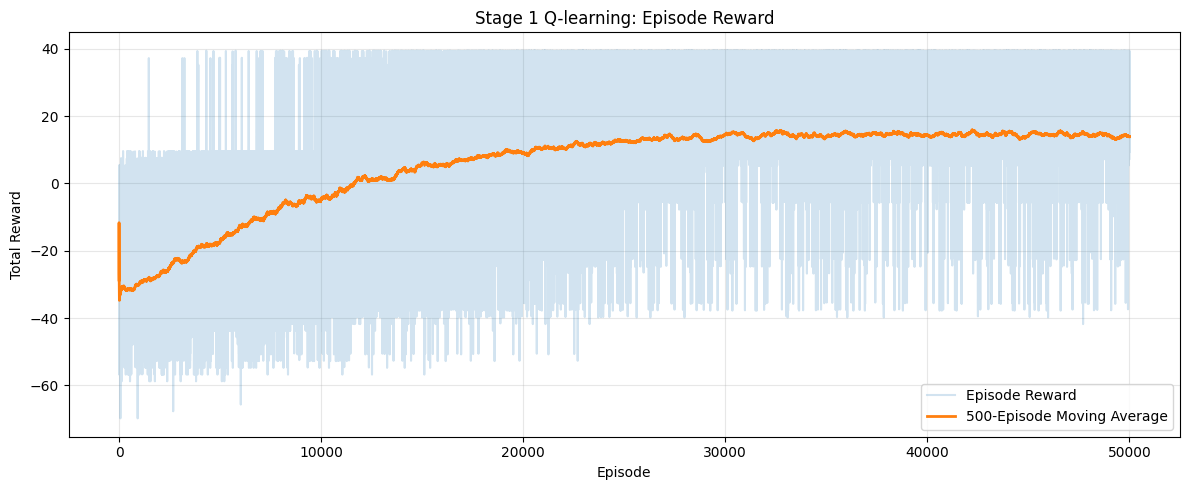

In [6]:
#===Episode Reward 그래프===
plt.figure(figsize=(12, 5))
plt.plot(history_df['episode'], history_df['reward'], alpha=0.20, label='Episode Reward')
plt.plot(history_df['episode'], history_df['moving_avg_reward'], linewidth=2, label=f'{WINDOW}-Episode Moving Average')
plt.title('Stage 1 Q-learning: Episode Reward')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

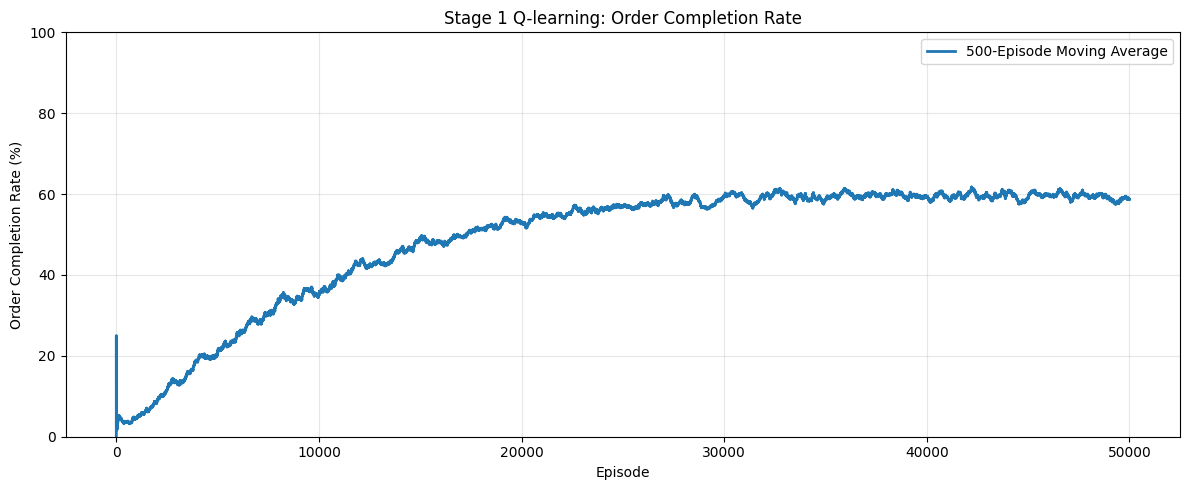

In [7]:
#===Order Completion Rate 그래프===
plt.figure(figsize=(12, 5))
plt.plot(history_df['episode'], history_df['moving_avg_completion'], linewidth=2, label=f'{WINDOW}-Episode Moving Average')
plt.title('Stage 1 Q-learning: Order Completion Rate')
plt.xlabel('Episode')
plt.ylabel('Order Completion Rate (%)')
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

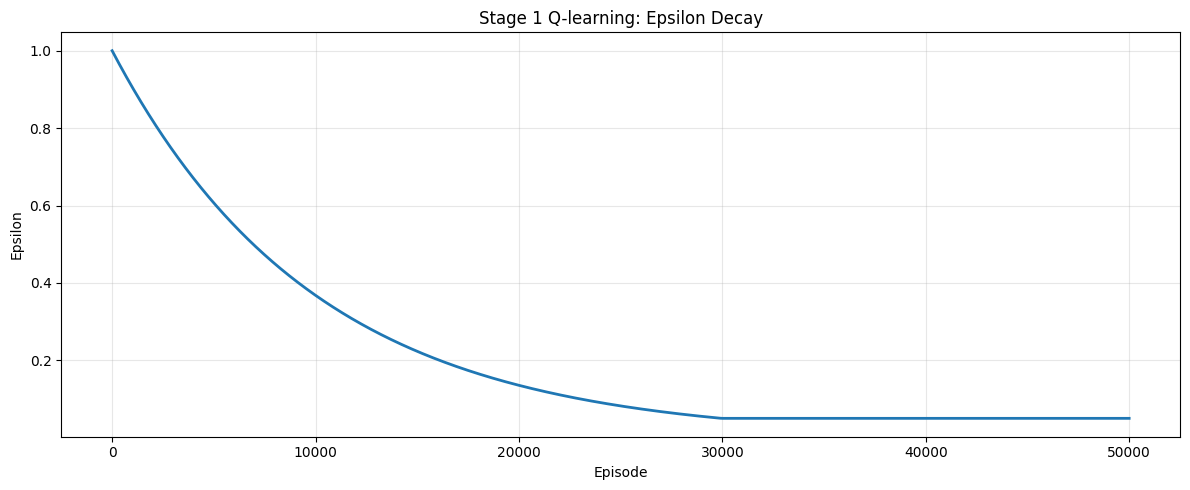

In [8]:
#===Epsilon Decay 그래프===
plt.figure(figsize=(12, 5))
plt.plot(history_df['episode'], history_df['epsilon'], linewidth=2)
plt.title('Stage 1 Q-learning: Epsilon Decay')
plt.xlabel('Episode')
plt.ylabel('Epsilon')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
#===Test Performance 결과 확인===
if PERFORMANCE_PATH.exists():
    performance_df = pd.read_csv(PERFORMANCE_PATH)
    display(performance_df)
else:
    print(f'성능 요약 파일이 없습니다: {PERFORMANCE_PATH}')
    print('학습 기록 그래프는 정상적으로 확인할 수 있습니다.')

,Evaluation Metric,Value
0,Total Evaluation Episodes,"1,000"
1,Average Reward (Return),17.47
2,Order Completion Rate (%),63.50%
3,Average Served Orders (Max 2),1.27 / 2.0
4,Average Expired Orders,0.73
5,Average Wrong Serves,0.00
6,Average Steps per Episode,6.08


In [10]:
#===그래프 데이터 저장===
GRAPH_DATA_PATH = RESULT_DIR / 'training_graph_data_stage1.csv'
history_df.to_csv(GRAPH_DATA_PATH, index=False, encoding='utf-8-sig')
print('Graph data saved to:', GRAPH_DATA_PATH)

Graph data saved to: /content/drive/MyDrive/pizza_rl_pj/results_stage1/training_graph_data_stage1.csv
